# plutovizu — Graphiques complexes

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Données d'exemple

Jeux de données fictifs utilisés dans ce notebook.

In [2]:
rng = np.random.default_rng(3)
lignes = []
for variete, gain in [('Sahel-108', 0.0), ('IR-841', 0.7), ('Nerica-4', 1.3)]:
    for dose in [0, 30, 60, 90, 120]:
        for bloc in range(1, 5):
            lignes.append({'variete': variete, 'dose': dose, 'bloc': bloc,
                           'rendement': 2.5 + gain + 0.035 * dose - 0.00018 * dose ** 2
                                        + rng.normal(0, 0.3)})
essai = pd.DataFrame(lignes)

rng = np.random.default_rng(7)
n = 20
precocite = rng.normal(size=n)
caracteres = pd.DataFrame({
    'variete': [f'V{i:02d}' for i in range(n)],
    'cycle': np.where(precocite > 0, 'tardif', 'précoce'),
    'hauteur': 95 + 12 * precocite + rng.normal(0, 5, n),
    'floraison': 85 + 10 * precocite + rng.normal(0, 3, n),
    'talles': 12 - 2 * precocite + rng.normal(0, 1, n),
    'pmg': 25 + rng.normal(0, 2.5, n),
    'rendement': 4.5 + 0.5 * precocite + rng.normal(0, 0.4, n),
})

## Graphiques complexes

Graphiques non triviaux : plusieurs couches, plusieurs axes ou plusieurs panneaux. Données **fictives**.

In [3]:
pertes = pd.DataFrame({
    'cause': ['Insectes du stock', 'Moisissures', 'Rongeurs', 'Égrenage au champ',
              'Transport', 'Séchage insuffisant', 'Vol', 'Oiseaux', 'Battage', 'Autres'],
    'tonnes': [182, 141, 96, 64, 38, 27, 15, 11, 7, 4]})

rng_c = np.random.default_rng(7)
lots = pd.DataFrame({'lot': np.arange(1, 31),
                     'humidite': np.round(13.2 + rng_c.normal(0, 0.35, 30), 2)})
lots.loc[[11, 23], 'humidite'] = [14.9, 11.6]   # deux lots hors limites

assolement = pd.DataFrame({
    'region': ['Nord'] * 4 + ['Centre'] * 4 + ['Sud'] * 4 + ['Est'] * 4,
    'culture': ['Mil', 'Sorgho', 'Arachide', 'Niébé'] * 4,
    'surface': [420, 260, 150, 90, 300, 210, 380, 160, 120, 90, 260, 70, 150, 180, 60, 110]})

rng_b = np.random.default_rng(3)
vrai = rng_b.uniform(8, 32, 40)
mesures = pd.DataFrame({'gravimetrie': np.round(vrai + rng_b.normal(0, 0.6, 40), 1),
                        'sonde': np.round(vrai * 0.97 + 1.2 + rng_b.normal(0, 1.0, 40), 1)})

### Diagramme de Pareto

Causes triées, pourcentage cumulé sur l'axe de droite et seuil des 80/20 : les causes « essentielles » sont en couleur pleine.

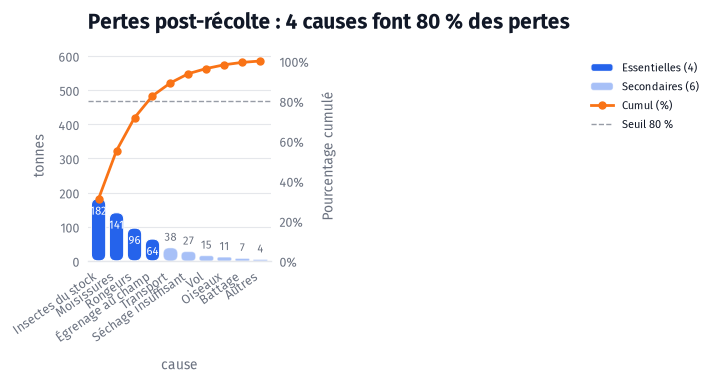

,cause,valeur,part,cumul,classe
0,Insectes du stock,182,31.1,31.1,essentielle
1,Moisissures,141,24.1,55.2,essentielle
2,Rongeurs,96,16.4,71.6,essentielle
3,Égrenage au champ,64,10.9,82.6,essentielle
4,Transport,38,6.5,89.1,secondaire
5,Séchage insuffisant,27,4.6,93.7,secondaire
6,Vol,15,2.6,96.2,secondaire
7,Oiseaux,11,1.9,98.1,secondaire
8,Battage,7,1.2,99.3,secondaire
9,Autres,4,0.7,100.0,secondaire


In [4]:
chart = (Chart(pertes)
    .pareto('cause', 'tonnes')
    .title('Pertes post-récolte : 4 causes font 80 % des pertes')
    .tight_layout())
chart.show()
chart.pareto_table

### Carte de contrôle

Limites moyenne ± 3 σ (σ = étendue mobile moyenne / 1,128) ; les lots hors limites ressortent.

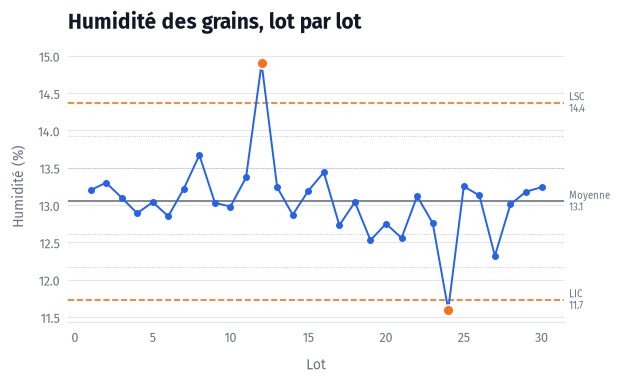

{'moyenne': np.float64(13.050333333333333),
 'sigma': np.float64(0.44020542920029343),
 'lsc': np.float64(14.370949620934212),
 'lic': np.float64(11.729717045732453)}

In [5]:
chart = (Chart(lots)
    .control_chart('lot', 'humidite')
    .title('Humidité des grains, lot par lot')
    .labels('Lot', 'Humidité (%)')
    .tight_layout())
chart.show()
chart.control_limits

### Marimekko, Bland-Altman et nuage de pluie

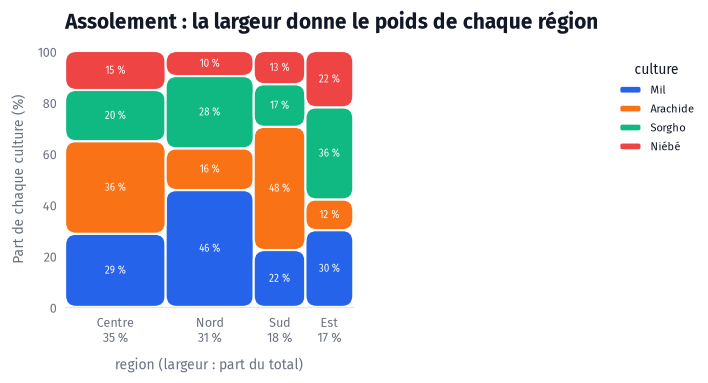

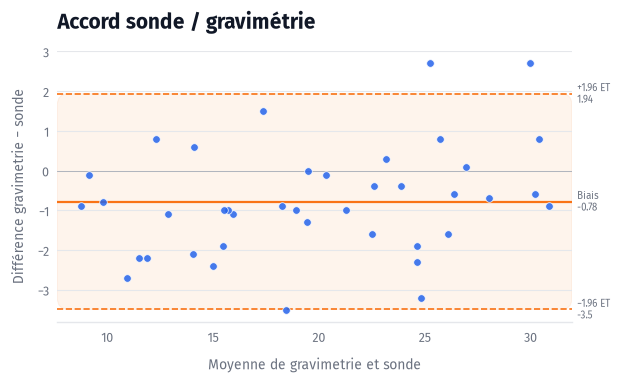

{'biais': np.float64(-0.7799999999999998), 'ecart_type': np.float64(1.3854925996156544), 'limite_basse': np.float64(-3.4955654952466824), 'limite_haute': np.float64(1.9355654952466828), 'hors_limites': 3, 'n': 40}


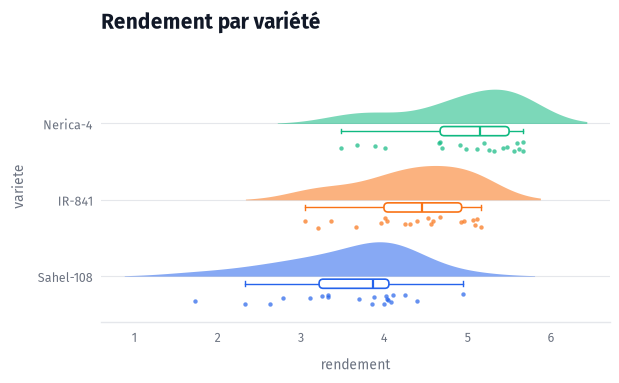

In [6]:
(Chart(assolement)
    .marimekko('region', 'culture', 'surface')
    .title('Assolement : la largeur donne le poids de chaque région')
    .tight_layout()
    .show())

chart = (Chart(mesures)
    .bland_altman('gravimetrie', 'sonde')
    .title('Accord sonde / gravimétrie')
    .tight_layout())
chart.show()
print(chart.agreement)

(Chart(essai)
    .raincloud('variete', 'rendement')
    .title('Rendement par variété')
    .tight_layout()
    .show())

### Seaborn

`chart.seaborn('nom')` donne accès à toutes les fonctions de seaborn ; les plus courantes ont un raccourci (`kde`, `swarm`, `relplot`, `catplot`…).

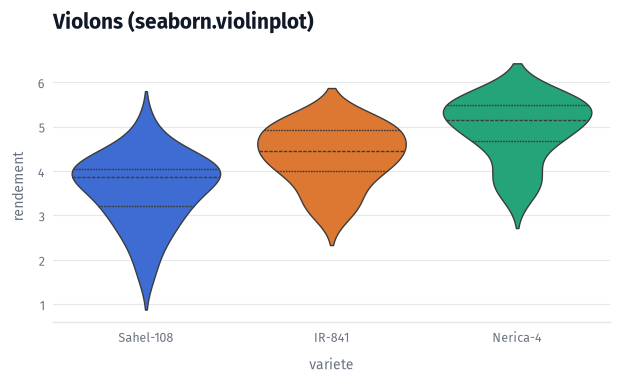

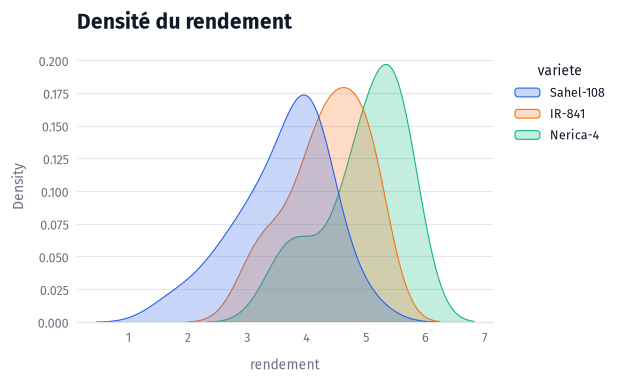

In [7]:
(Chart(essai)
    .seaborn('violinplot', x='variete', y='rendement', hue='variete', inner='quart')
    .title('Violons (seaborn.violinplot)')
    .tight_layout()
    .show())

(Chart(essai)
    .kde('rendement', hue='variete')
    .title('Densité du rendement')
    .tight_layout()
    .show())

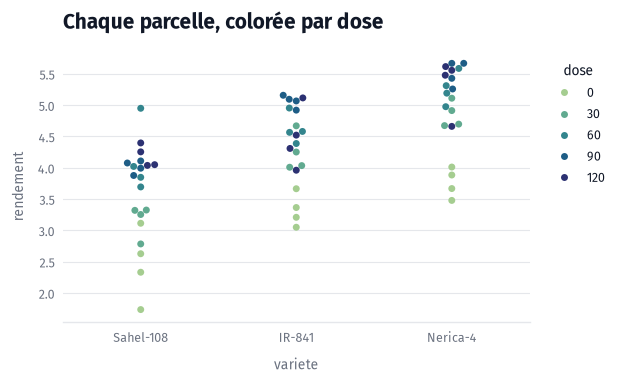

In [8]:
(Chart(essai)
    .swarm('variete', 'rendement', hue='dose', palette='crest')
    .title('Chaque parcelle, colorée par dose')
    .tight_layout()
    .show())

### Grilles seaborn

`relplot`, `displot`, `catplot`, `lmplot`, `jointplot`, `pairplot` et `clustermap` créent une grille de panneaux : `title()` devient le titre général ; taille par `height` et `aspect`.

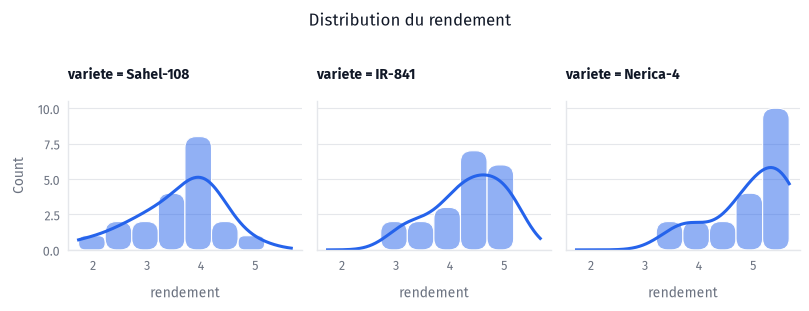

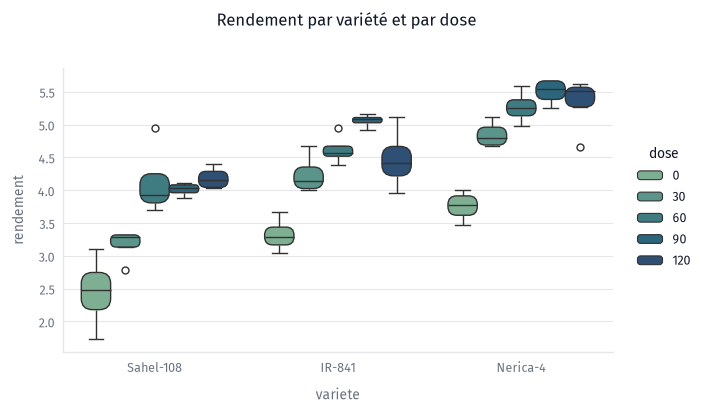

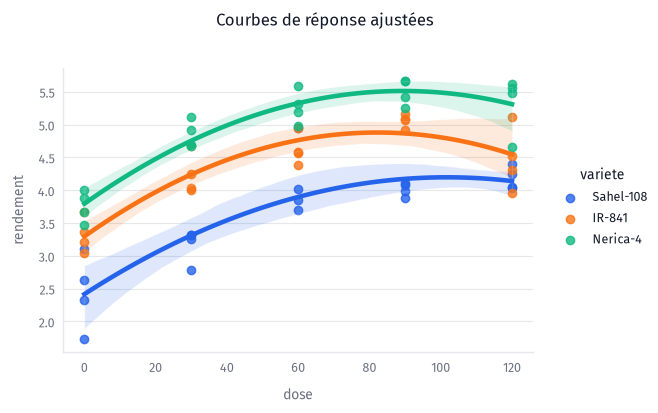

In [9]:
(Chart(essai)
    .displot('rendement', col='variete', kde=True, bins=8, height=3, aspect=0.9)
    .title('Distribution du rendement')
    .tight_layout()
    .show())

(Chart(essai.assign(dose=essai['dose'].astype(str)))
    .catplot('variete', 'rendement', hue='dose', kind='box', height=4, aspect=1.6, palette='crest')
    .title('Rendement par variété et par dose')
    .tight_layout()
    .show())

(Chart(essai)
    .lmplot('dose', 'rendement', hue='variete', order=2, height=4, aspect=1.4)
    .title('Courbes de réponse ajustées')
    .tight_layout()
    .show())

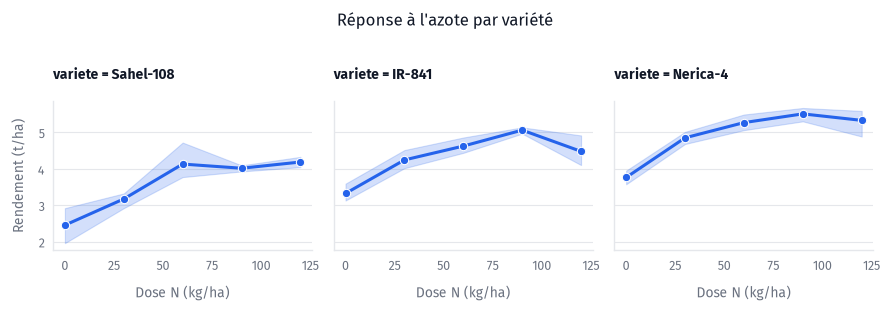

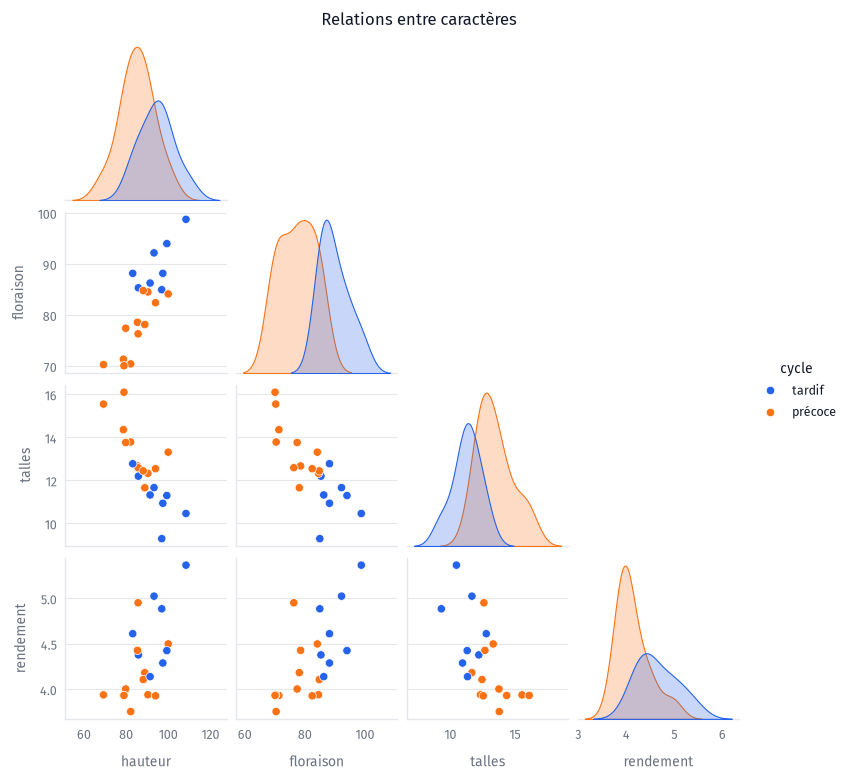

In [10]:
(Chart(essai)
    .relplot('dose', 'rendement', col='variete', kind='line', marker='o', height=3)
    .title("Réponse à l'azote par variété")
    .labels('Dose N (kg/ha)', 'Rendement (t/ha)')
    .tight_layout()
    .show())

(Chart(caracteres)
    .pairplot(vars=['hauteur', 'floraison', 'talles', 'rendement'], hue='cycle', corner=True, height=1.9)
    .title('Relations entre caractères')
    .show())